# 6. Demanda, clima e hidrología

El análisis numérico utiliza el periodo completo de desarrollo **2000–2021**. Los ajustes de escaladores y modelos se realizan dentro de cada fold.

Se estiman asociaciones contemporáneas, asociaciones con covariables rezagadas 24 horas y acumulados hidrológicos retrospectivos. La información mutua se calcula sobre una muestra determinista de 12.000 horas de desarrollo; las correlaciones y los resúmenes utilizan todas las observaciones disponibles de 2000–2021. Estas medidas describen dependencias estadísticas y orientan la representación multivariada.

Las ocho ciudades se conservan por separado para representar la heterogeneidad meteorológica. El objetivo de pronóstico es una serie nacional. La precipitación urbana caracteriza las ubicaciones seleccionadas; representar la oferta hidroeléctrica mediante lluvia requiere observaciones adicionales en las cuencas aportantes.


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from IPython.display import Markdown, display
import datetime as dt
import hashlib
import json
from sklearn.feature_selection import mutual_info_regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

In [2]:
RESULTS = ROOT / 'results'
SEED = 11037
TARGET = 'precio_bolsa_cop_kwh'
ALLOWED_SOURCES = {'El Tiempo', 'El Espectador', 'Semana', 'Portafolio', 'La República', 'El Colombiano', 'Dinero', 'IDEAM', 'XM'}
EDA_SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
SPLITS = EDA_SPLITS
TIME = 'timestamp_start_colombia'
WEATHER_PREFIXES = ('temperature_2m_c_', 'relative_humidity_2m_pct_', 'precipitation_preceding_hour_mm_')
CITIES = {'bogota', 'medellin', 'cali', 'barranquilla', 'cartagena', 'bucaramanga', 'pereira', 'cucuta'}
NUMERIC_E1 = {TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh', 'llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia'}
PIPELINE_DEFAULTS = {'method': 'split_train_val_forwardChaining', 'n_splits': 5, 'development_start': '2000-01-01T00:00:00-05:00', 'validation_start': '2018-01-01T00:00:00-05:00', 'development_end_exclusive': '2022-01-01T00:00:00-05:00', 'test_start': '2022-01-01T00:00:00-05:00', 'test_end_exclusive': '2026-01-01T00:00:00-05:00', 'lookback_hours': 168, 'horizon_hours': 24, 'stride_hours': 24, 'hourly_release_lag_hours': 24, 'hydrology_release_lag_days': 2, 'include_calendar': True, 'seed': 11037, 'availability_scenario': 'retrospective_assumed_release_lags'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def aware(value):
    parsed = dt.datetime.fromisoformat(value.replace('Z', '+00:00'))
    if parsed.tzinfo is None:
        raise ValueError('Timestamp must have an explicit timezone')
    return parsed

In [4]:
def eligible(record, origin):
    cutoff = aware(origin)
    if (record.get('source') or record.get('medium')) not in ALLOWED_SOURCES:
        return False
    if record.get('availability_status') != 'verified_archived_version':
        return False
    if record.get('availability_proof') != 'wayback_payload_digest_and_capture':
        return False
    clean_flag = record.get('quarantined', False) in (False, 0, None, '', '0', 'false', 'False')
    if not re.fullmatch('[0-9a-f]{64}', record.get('version_sha256') or '') or not clean_flag:
        return False
    available = record.get('available_at_verified')
    captured = record.get('capture_at_verified')
    if not available or not captured:
        return False
    return aware(captured) <= aware(available) <= cutoff

In [5]:
def split_train_val_forwardChaining(sequence, numInputs, numOutputs, numJumps):
    """ Returns sets to train and cross-validate a model using forward chaining technique
    
    Parameters:
        sequence (array)  : Full training dataset
        numInputs (int)   : Number of inputs X and Xcv used at each training and validation
        numOutputs (int)  : Number of outputs y and ycv used at each training and validation
        numJumps (int)    : Number of sequence samples to be ignored between (X,y) sets

    Returns:
        X (2D array)    : Array of numInputs arrays used for training
        y (2D array)    : Array of numOutputs arrays used for training
        Xcv (2D array)  : Array of numInputs arrays used for cross-validation
        ycv (2D array)  : Array of numOutputs arrays used for cross-validation
        
    

Fuente: timeseries-cv 0.1.5; licencia original:
MIT License

Copyright (c) 2021 DidierRLopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

The MIT License (MIT)

Copyright (c) 2019 Didier Rodrigues Lopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
"""
    X, y, Xcv, ycv = (dict(), dict(), dict(), dict())
    j = 2
    while 1:
        start_ix = 0
        end_ix = 0
        startCv_ix = 0
        endCv_ix = 0
        X_it, y_it, Xcv_it, ycv_it = (list(), list(), list(), list())
        i = 0
        while i < j:
            start_ix = numJumps * i
            end_ix = start_ix + numInputs
            seq_x = sequence[start_ix:end_ix]
            X_it.append(seq_x)
            seq_y = sequence[end_ix:end_ix + numOutputs]
            y_it.append(seq_y)
            i += 1
        if end_ix + numInputs + numOutputs > len(sequence):
            break
        startCv_ix = end_ix
        endCv_ix = end_ix + numInputs
        seq_xcv = sequence[startCv_ix:endCv_ix]
        Xcv_it.append(seq_xcv)
        seq_ycv = sequence[endCv_ix:endCv_ix + numOutputs]
        ycv_it.append(seq_ycv)
        X[j - 2] = np.array(X_it)
        y[j - 2] = np.array(y_it)
        Xcv[j - 2] = np.array(Xcv_it)
        ycv[j - 2] = np.array(ycv_it)
        j += 1
    if len(X) == 0 or len(Xcv) == 0:
        print('The sequence provided does not has size enough to populate the return arrays')
    return (X, y, Xcv, ycv)

In [6]:
def validate_development_index(index, config):
    index = pd.DatetimeIndex(index)
    if index.tz is None:
        raise ValueError('El índice debe tener zona horaria.')
    index = index.tz_convert('America/Bogota')
    if len(index) < 2 or not index.is_monotonic_increasing or index.has_duplicates:
        raise ValueError('Índice temporal desordenado, duplicado o insuficiente.')
    if not np.all(np.diff(index.as_unit('ns').asi8) == pd.Timedelta(hours=1).value):
        raise ValueError('El calendario horario contiene huecos.')
    if index[0] < pd.Timestamp(config['development_start']) or index[-1] >= pd.Timestamp(config['development_end_exclusive']):
        raise PermissionError('La preparación sólo admite el periodo de desarrollo.')
    return index

In [7]:
def forward_chaining_folds(index, config, input_usable=None, target_usable=None):
    """Plan temporal por bloques; ventanas supervisadas completas y sin etiquetas compartidas."""
    index = validate_development_index(index, config)
    length = len(index)
    lookback = config['lookback_hours']
    horizon = config['horizon_hours']
    origins = np.arange(lookback, length - horizon + 1, config['stride_hours'], dtype=np.int64)
    origins = origins[index[origins].hour == 0]
    if input_usable is not None:
        flags = np.asarray(input_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de entradas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins] - bad[origins - lookback] == 0]
    if target_usable is not None:
        flags = np.asarray(target_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de etiquetas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins + horizon] - bad[origins] == 0]
    initial = origins[index[origins] < pd.Timestamp(config['validation_start'])]
    eligible = origins[index[origins] >= pd.Timestamp(config['validation_start'])]
    if len(initial) < 3 or len(eligible) < config['n_splits']:
        raise ValueError('Datos insuficientes para los folds.')
    validation_blocks = np.array_split(eligible, config['n_splits'])
    train_x, train_y, val_x, val_y = split_train_val_forwardChaining(np.arange(config['n_splits'] + 3), 1, 1, 1)
    if len(val_y) != config['n_splits']:
        raise AssertionError('Número inesperado de folds del backend')
    folds = []
    for key in sorted(val_y):
        block = int(val_y[key].ravel()[0])
        block_id = block - 3
        past_blocks = np.unique(np.r_[train_x[key].ravel(), train_y[key].ravel()])
        if past_blocks.max() >= block:
            raise AssertionError('El backend incluyó bloques futuros')
        start = int(validation_blocks[block_id][0])
        stop = int(validation_blocks[block_id + 1][0]) if block_id + 1 < len(validation_blocks) else length
        train = origins[origins + horizon <= start]
        validation = validation_blocks[block_id]
        validation = validation[validation + horizon <= stop]
        if not len(train) or not len(validation):
            raise ValueError('Fold vacío tras la purga de etiquetas')
        assert train[-1] + horizon <= validation[0]
        digest = hashlib.sha256(train.astype('<i8').tobytes() + validation.astype('<i8').tobytes()).hexdigest()
        folds.append(dict(fold=len(folds) + 1, train_origins=train, validation_origins=validation, validation_block=block, indices_sha256=digest))
    return folds

In [8]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [9]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [10]:
def load_development_data(table='hourly'):
    return pd.concat([load_numeric('train', table=table), load_numeric('validation', table=table)]).sort_index()

In [11]:
def assert_e1_features(names):
    for name in names:
        if name in NUMERIC_E1:
            continue
        if any((name == prefix + city for prefix in WEATHER_PREFIXES for city in CITIES)):
            continue
        if name in {'hour_sin', 'hour_cos', 'week_sin', 'week_cos', 'year_sin', 'year_cos'}:
            continue
        raise ValueError('E1 sólo admite las variables numéricas declaradas: ' + name)
    return True

In [12]:
def numeric_feature_frame(hourly, hydrology, config):
    index = validate_development_index(hourly.index, config)
    if not hydrology.index.is_monotonic_increasing or hydrology.index.has_duplicates:
        raise ValueError('Índice hidrológico no válido.')
    if hydrology.index.tz is None or (len(hydrology) and hydrology.index[-1] >= pd.Timestamp(config['development_end_exclusive'])):
        raise PermissionError('Hidrología fuera del periodo de desarrollo o sin zona horaria.')
    columns = [TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh']
    columns += sorted((c for c in hourly.columns if c.startswith(WEATHER_PREFIXES)))
    features = hourly[columns].shift(config['hourly_release_lag_hours']).copy()
    hydro_columns = ['llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia']
    released = hydrology[hydro_columns].copy()
    released.index = released.index + pd.Timedelta(days=config['hydrology_release_lag_days'])
    features = features.join(released.reindex(index, method='ffill'))
    if config['include_calendar']:
        phases = {'hour': index.hour / 24, 'week': (index.day_of_week + index.hour / 24) / 7, 'year': (index.day_of_year - 1 + index.hour / 24) / np.where(index.is_leap_year, 366, 365)}
        for name, phase in phases.items():
            features[name + '_sin'] = np.sin(2 * np.pi * phase)
            features[name + '_cos'] = np.cos(2 * np.pi * phase)
    assert_e1_features(features.columns)
    return features

In [13]:
def pipeline_config(overrides=None):
    config = dict(PIPELINE_DEFAULTS)
    if overrides:
        unknown = set(overrides) - set(config)
        if unknown:
            raise ValueError('Opciones desconocidas: ' + str(sorted(unknown)))
        config.update(overrides)
    for field in ['n_splits', 'lookback_hours', 'horizon_hours', 'stride_hours']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 1:
            raise ValueError('Se requiere un entero positivo: ' + field)
    for field in ['hourly_release_lag_hours', 'hydrology_release_lag_days']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 0:
            raise ValueError('Rezago inválido: ' + field)
    if config['hydrology_release_lag_days'] < 1:
        raise ValueError('La hidrología diaria requiere al menos el cierre del día.')
    for field in ['development_start', 'validation_start', 'development_end_exclusive', 'test_start', 'test_end_exclusive']:
        if pd.Timestamp(config[field]).tzinfo is None:
            raise ValueError('Se requiere zona horaria: ' + field)
    if config['method'] != 'split_train_val_forwardChaining':
        raise ValueError('Método no autorizado')
    if pd.Timestamp(config['test_start']) != pd.Timestamp(PIPELINE_DEFAULTS['test_start']) or config['test_end_exclusive'] != PIPELINE_DEFAULTS['test_end_exclusive']:
        raise ValueError('El periodo de prueba está congelado.')
    if not pd.Timestamp(config['development_start']) < pd.Timestamp(config['validation_start']) < pd.Timestamp(config['development_end_exclusive']) <= pd.Timestamp(config['test_start']):
        raise ValueError('Cortes temporales inválidos')
    if config['stride_hours'] % 24:
        raise ValueError('Los orígenes deben conservar el paso diario.')
    return config

In [14]:
def build_training_pipeline(config=None, hourly=None, hydrology=None):
    config = pipeline_config(config)
    hourly = load_development_data() if hourly is None else hourly
    hydrology = load_development_data('hydrology') if hydrology is None else hydrology
    features = numeric_feature_frame(hourly, hydrology, config)
    target = hourly[TARGET].copy()
    usable = np.isfinite(features.to_numpy()).all(axis=1)
    folds = forward_chaining_folds(features.index, config, usable, np.isfinite(target.to_numpy()))
    return dict(config=config, features=features, target=target, folds=folds)

In [15]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [16]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [17]:
def load_pipeline_config(path=None):
    path = ROOT / 'configs/training_pipeline.json' if path is None else path
    return pipeline_config(json.loads(path.read_text(encoding='utf-8')))

In [18]:
def load_eda_development(table='hourly'):
    """Desarrollo completo; no cambia las particiones que usa el entrenamiento."""
    config = load_pipeline_config()
    frame = load_development_data(table)
    if len(frame) and frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('La fuente contiene fechas de prueba.')
    start = pd.Timestamp(config['development_start'])
    end = pd.Timestamp(config['development_end_exclusive'])
    frame = frame.loc[(frame.index >= start) & (frame.index < end)]
    if frame.empty or frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('El EDA sólo admite desarrollo anterior a prueba.')
    return frame

In [19]:
def used_window_rows(origins, length, lookback, horizon):
    """Filas únicas y multiplicidad de entradas/etiquetas sin materializar ventanas."""
    origins = np.asarray(origins, dtype=np.int64)
    if origins.ndim != 1 or not len(origins):
        raise ValueError('Se requieren orígenes unidimensionales no vacíos.')
    if lookback < 1 or horizon < 1 or np.any(origins < lookback) or np.any(origins + horizon > length):
        raise ValueError('Una ventana atraviesa los límites del calendario.')

    def counts(left, right):
        delta = np.zeros(length + 1, dtype=np.int64)
        np.add.at(delta, left, 1)
        np.add.at(delta, right, -1)
        return np.cumsum(delta[:-1])
    inputs = counts(origins - lookback, origins)
    labels = counts(origins, origins + horizon)
    return (inputs, labels)

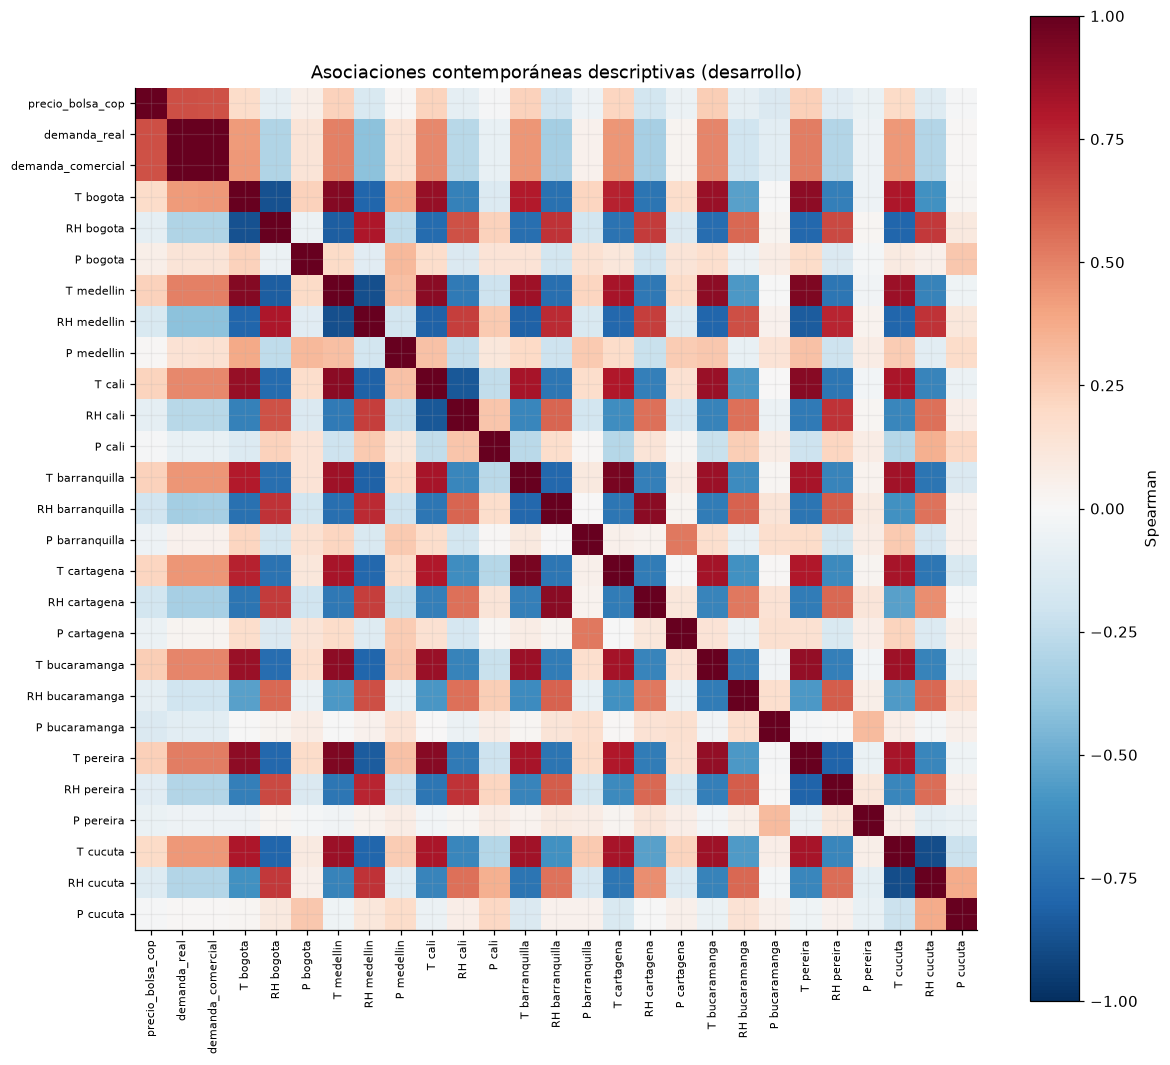

In [20]:
frame = load_eda_development()
hydro = load_eda_development(table='hydrology')
numeric = frame.select_dtypes('number').drop(columns=['xm_hour'], errors='ignore')
corr = numeric.corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
labels = [c.replace('relative_humidity_2m_pct_', 'RH ').replace('temperature_2m_c_', 'T ').replace('precipitation_preceding_hour_mm_', 'P ').replace('_kwh', '') for c in corr]
ax.set_xticks(range(len(corr)), labels, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), labels, fontsize=7)
fig.colorbar(im, ax=ax, label='Spearman')
ax.set_title('Asociaciones contemporáneas descriptivas (desarrollo)')
figure(fig, 'correlaciones_desarrollo')

In [21]:
table(corr[[TARGET]].sort_values(TARGET), 'correlacion_contemporanea_desarrollo')

,precio_bolsa_cop_kwh
relative_humidity_2m_pct_barranquilla,-0.18964
relative_humidity_2m_pct_cartagena,-0.18329
relative_humidity_2m_pct_medellin,-0.15601
precipitation_preceding_hour_mm_bucaramanga,-0.14346
relative_humidity_2m_pct_cucuta,-0.12771
relative_humidity_2m_pct_pereira,-0.11528
relative_humidity_2m_pct_bucaramanga,-0.088227
relative_humidity_2m_pct_cali,-0.086752
relative_humidity_2m_pct_bogota,-0.086103
precipitation_preceding_hour_mm_pereira,-0.066521


In [22]:
predictors = numeric.drop(columns=TARGET).shift(24)
aligned = predictors.join(frame[TARGET]).dropna()
rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(aligned), min(12000, len(aligned)), replace=False))
sample = aligned.iloc[idx]
mi = mutual_info_regression(sample.drop(columns=TARGET), sample[TARGET], n_neighbors=5, random_state=SEED)
lagged = pd.DataFrame({'spearman_rezago_24h': aligned.corr(method='spearman')[TARGET].drop(TARGET), 'informacion_mutua_muestra_desarrollo': mi}, index=predictors.columns).sort_values('spearman_rezago_24h')
table(lagged, 'asociaciones_rezagadas_desarrollo')

,spearman_rezago_24h,informacion_mutua_muestra_desarrollo
relative_humidity_2m_pct_barranquilla,-0.19261,0.043141
relative_humidity_2m_pct_cartagena,-0.18556,0.038304
relative_humidity_2m_pct_medellin,-0.16088,0.024517
precipitation_preceding_hour_mm_bucaramanga,-0.14919,0.032759
relative_humidity_2m_pct_cucuta,-0.13415,0.033156
relative_humidity_2m_pct_pereira,-0.11842,0.0069202
relative_humidity_2m_pct_bucaramanga,-0.094557,0.013255
relative_humidity_2m_pct_bogota,-0.091627,0.018885
relative_humidity_2m_pct_cali,-0.088247,0.013143
precipitation_preceding_hour_mm_pereira,-0.067975,0.018304


In [23]:
x = numeric.drop(columns=TARGET)
std = x.std()
z = (x - x.mean()) / std.replace(0, np.nan)
matrix = z.dropna(axis=1).to_numpy()
condition = np.linalg.cond(matrix[::24])
gram = np.corrcoef(matrix[::24], rowvar=False)
vif = np.diag(np.linalg.pinv(gram))
table(pd.DataFrame({'VIF_aproximado': vif}, index=z.dropna(axis=1).columns).sort_values('VIF_aproximado', ascending=False), 'colinealidad_desarrollo')

,VIF_aproximado
demanda_real_kwh,1415.3
demanda_comercial_kwh,1414
temperature_2m_c_barranquilla,10.875
temperature_2m_c_cartagena,8.5492
relative_humidity_2m_pct_barranquilla,6.9684
relative_humidity_2m_pct_cartagena,4.6246
temperature_2m_c_cucuta,4.3457
temperature_2m_c_cali,4.22
relative_humidity_2m_pct_cucuta,3.8927
temperature_2m_c_bucaramanga,3.2817


In [24]:
display(Markdown(f'Número de condición de la matriz estandarizada diaria de covariables: **{condition:.4g}**. El VIF usa pseudoinversa si hay singularidad; se interpreta junto al número de condición, no como identificación causal.'))

Número de condición de la matriz estandarizada diaria de covariables: **210.3**. El VIF usa pseudoinversa si hay singularidad; se interpreta junto al número de condición, no como identificación causal.

In [25]:
daily = frame[TARGET].resample('D').mean()
h = hydro.select_dtypes('number')
changes = pd.DataFrame({'precio_diario': daily, 'reserva_rezago_1d': h['reserva_util_kwh'].shift(1), 'aportes_acumulados_7d_pasados': h['aportes_kwh_dia'].shift(1).rolling(7).sum(), 'cambio_reserva_7d_pasado': h['reserva_util_kwh'].shift(1) - h['reserva_util_kwh'].shift(8)})
table(changes.corr(method='spearman'), 'hidrologia_cambios_pasados_desarrollo')

,precio_diario,reserva_rezago_1d,aportes_acumulados_7d_pasados,cambio_reserva_7d_pasado
precio_diario,1,-0.23569,-0.15116,-0.24923
reserva_rezago_1d,-0.23569,1,0.35394,0.09316
aportes_acumulados_7d_pasados,-0.15116,0.35394,1,0.82243
cambio_reserva_7d_pasado,-0.24923,0.09316,0.82243,1


In [26]:
weather = []
for c in numeric:
    if any((s in c for s in ['temperature', 'humidity', 'precipitation'])):
        weather.append(dict(variable=c, media=numeric[c].mean(), sd=numeric[c].std(), p01=numeric[c].quantile(0.01), p99=numeric[c].quantile(0.99)))
table(pd.DataFrame(weather).set_index('variable'), 'heterogeneidad_ciudades_desarrollo')

,media,sd,p01,p99
variable,,,,
temperature_2m_c_bogota,14.884,3.4523,9,22.6
relative_humidity_2m_pct_bogota,76.062,18.819,32,100
precipitation_preceding_hour_mm_bogota,0.11357,0.39781,0,1.8
temperature_2m_c_medellin,21.114,3.5114,15.7,29.2
relative_humidity_2m_pct_medellin,84.397,15.399,43,100
precipitation_preceding_hour_mm_medellin,0.31745,0.71837,0,3.5
temperature_2m_c_cali,22.363,2.8095,17.6,28.6
relative_humidity_2m_pct_cali,83.786,9.4603,59,98
precipitation_preceding_hour_mm_cali,0.34987,0.94161,0,4.6


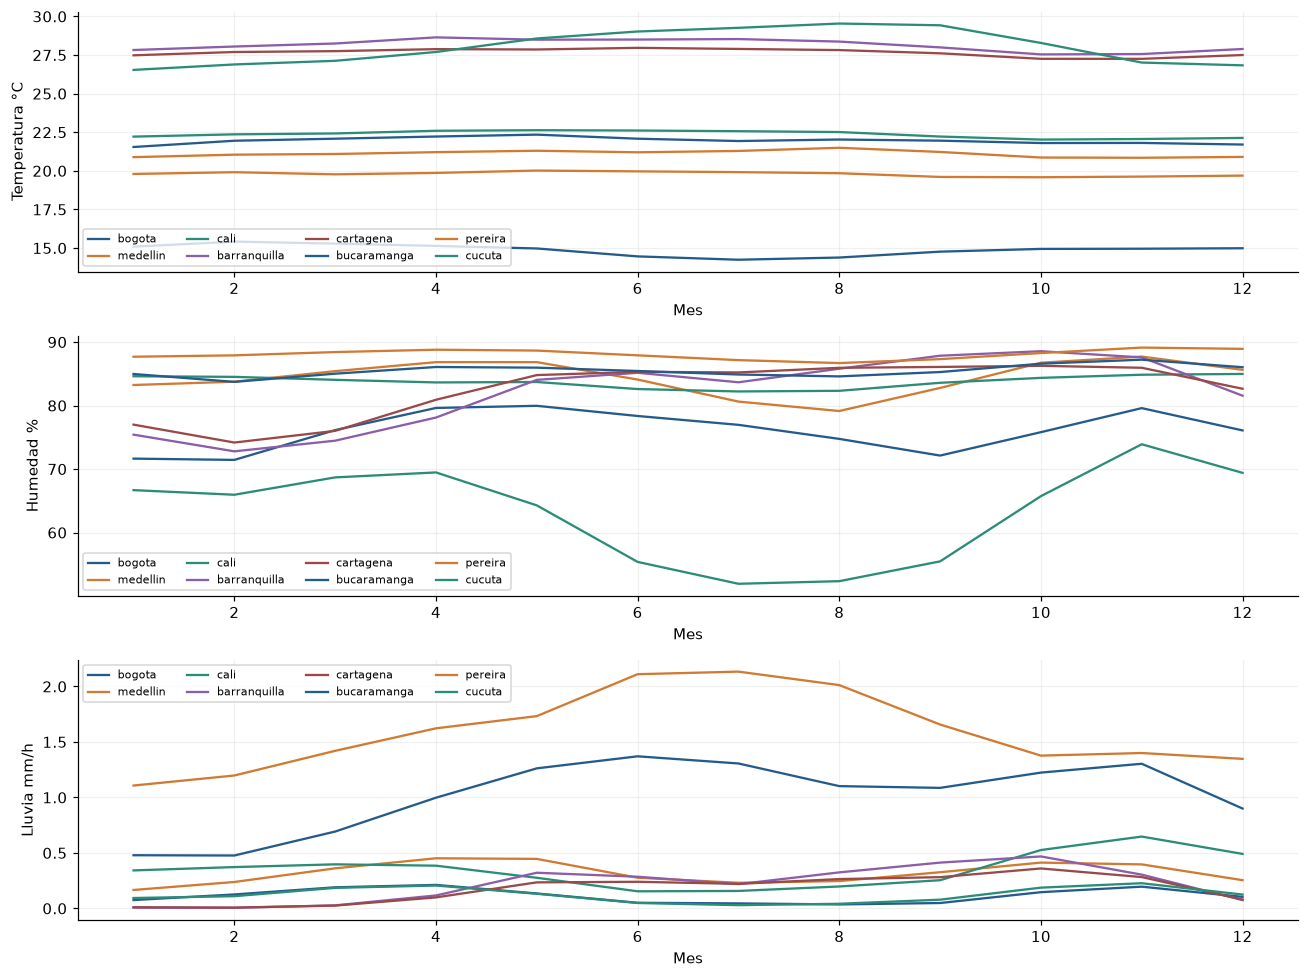

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, prefix, label in zip(axes, ['temperature', 'relative_humidity', 'precipitation'], ['Temperatura °C', 'Humedad %', 'Lluvia mm/h']):
    cols = [c for c in numeric if c.startswith(prefix)]
    means = numeric[cols].groupby(frame.index.month).mean()
    means.columns = [c.rsplit('_', 1)[-1] for c in cols]
    means.plot(ax=ax)
    ax.set(xlabel='Mes', ylabel=label)
    ax.legend(ncol=4, fontsize=7)
figure(fig, 'clima_por_ciudad_desarrollo')

In [28]:
decision('Conservar las ocho ciudades. Acumulados y cambios sólo hacia atrás; estandarización/selección sólo con train.', 'Bloques numéricos de demanda, clima e hidrología y fusión aprendida; regularizar ante covariables redundantes.', 'Asociaciones contemporáneas y con rezago son EDA retrospectivo, no evidencia de información conocida ni ganancia fuera de muestra.', 'Demanda realizada del horizonte y clima futuro realizado producirían fuga. Un día de rezago hidrológico es ilustración, no un rezago de publicación certificado. Lluvia urbana no reemplaza lluvia de cuencas aportantes; esta última no está descargada.')

### Implicaciones del análisis

- **Preprocesamiento:** Conservar las ocho ciudades. Acumulados y cambios sólo hacia atrás; estandarización/selección sólo con train.
- **Arquitectura:** Bloques numéricos de demanda, clima e hidrología y fusión aprendida; regularizar ante covariables redundantes.
- **Validación:** Asociaciones contemporáneas y con rezago son EDA retrospectivo, no evidencia de información conocida ni ganancia fuera de muestra.
- **Riesgos:** Demanda realizada del horizonte y clima futuro realizado producirían fuga. Un día de rezago hidrológico es ilustración, no un rezago de publicación certificado. Lluvia urbana no reemplaza lluvia de cuencas aportantes; esta última no está descargada.

## 6.1 Datos efectivos de entrenamiento

Se describen las 37 entradas numéricas alineadas mediante el mismo constructor del entrenamiento: precio, dos demandas, 24 variables meteorológicas, cuatro hidrológicas y seis componentes cíclicas de calendario. Los resúmenes cuentan cada hora de entrada una vez; las ventanas superpuestas repiten esas filas durante el ajuste.

La auditoría reproduce los cinco folds y los contextos de 24, 72, 168 y 336 horas. La búsqueda comparte orígenes determinados por la ventana máxima. Se contrasta la cobertura con sus archivos de preparación y se reconstruyen las filas del reajuste histórico en todo desarrollo para verificar sus medias y escalas guardadas. La descripción agregada no se utiliza para estimar el escalado de los folds.

In [29]:
config = load_pipeline_config()
pilot = build_training_pipeline(config)
search = build_training_pipeline(dict(config, lookback_hours=336))
features = pilot['features']
index = features.index
horizon = config['horizon_hours']
rows = []
coverage = []
saved_audit = json.loads((ROOT / 'results/variant_search/fold_audit.json').read_text(encoding='utf-8'))
for history in [24, 72, 168, 336]:
    for fold in search['folds']:
        train, valid = (fold['train_origins'], fold['validation_origins'])
        train_inputs, train_labels = used_window_rows(train, len(index), history, horizon)
        valid_inputs, valid_labels = used_window_rows(valid, len(index), history, horizon)
        assert not np.any((train_labels > 0) & (valid_labels > 0))
        assert index[np.flatnonzero(train_inputs)[-1]] < index[valid[0]]
        record = next((a for a in saved_audit if a['lookback'] == history and a['fold'] == fold['fold']))
        assert len(train) == record['n_train'] and len(valid) == record['n_validation']
        assert str(index[valid[0]]) == record['validation_start']
        assert list(features.columns) == record['feature_names']
        train_values = pilot['target'].iloc[np.flatnonzero(train_labels)]
        valid_values = pilot['target'].iloc[np.flatnonzero(valid_labels)]
        rows.append(dict(historia_horas=history, fold=fold['fold'], ventanas_train=len(train), ventanas_validacion=len(valid), filas_entrada_train=int((train_inputs > 0).sum()), horas_etiqueta_train=int((train_labels > 0).sum()), entrada_desde=str(index[np.flatnonzero(train_inputs)[0]]), entrada_hasta=str(index[np.flatnonzero(train_inputs)[-1]]), etiquetas_train_hasta=str(index[np.flatnonzero(train_labels)[-1]]), validacion_desde=str(index[valid[0]]), media_precio_train=float(train_values.mean()), media_precio_validacion=float(valid_values.mean()), q99_precio_train=float(train_values.quantile(0.99)), q99_precio_validacion=float(valid_values.quantile(0.99))))
    all_origins = np.unique(np.concatenate([search['folds'][0]['train_origins']] + [f['validation_origins'] for f in search['folds']]))
    used, labels = used_window_rows(all_origins, len(index), history, horizon)
    coverage.append(dict(historia_horas=history, ventanas_desarrollo=len(all_origins), filas_entrada_unicas=int((used > 0).sum()), horas_etiqueta_unicas=int((labels > 0).sum()), celdas_entrada_totales=int(used.sum() * features.shape[1]), multiplicidad_maxima_hora=int(used.max())))
table(pd.DataFrame(rows).set_index(['historia_horas', 'fold']), 'eda_entrenamiento_folds_contextos')

ventanas_train  ventanas_validacion  filas_entrada_train  \
historia_horas fold                                                             
24             1               6559                  293               157416   
               2               6852                  292               164448   
               3               7144                  292               171456   
               4               7436                  292               178464   
               5               7728                  292               185472   
72             1               6559                  293               157464   
               2               6852                  292               164496   
               3               7144                  292               171504   
               4               7436                  292               178512   
               5               7728                  292               185520   
168            1               6559                  293               157560   
               2               6852                  292               164592   
               3               7144                  292               171600   
               4               7436                  292               178608   
               5               7728                  292               185616   
336            1               6559                  293               157728   
               2               6852                  292               164760   
               3               7144                  292               171768   
               4               7436                  292               178776   
               5               7728                  292               185784   

                     horas_etiqueta_train              entrada_desde  \
historia_horas fold                                                    
24             1                   157416  2000-01-16 00:00:00-05:00   
               2                   164448  2000-01-16 00:00:00-05:00   
               3                   171456  2000-01-16 00:00:00-05:00   
               4                   178464  2000-01-16 00:00:00-05:00   
               5                   185472  2000-01-16 00:00:00-05:00   
72             1                   157416  2000-01-14 00:00:00-05:00   
               2                   164448  2000-01-14 00:00:00-05:00   
               3                   171456  2000-01-14 00:00:00-05:00   
               4                   178464  2000-01-14 00:00:00-05:00   
               5                   185472  2000-01-14 00:00:00-05:00   
168            1                   157416  2000-01-10 00:00:00-05:00   
               2                   164448  2000-01-10 00:00:00-05:00   
               3                   171456  2000-01-10 00:00:00-05:00   
               4                   178464  2000-01-10 00:00:00-05:00   
               5                   185472  2000-01-10 00:00:00-05:00   
336            1                   157416  2000-01-03 00:00:00-05:00   
               2                   164448  2000-01-03 00:00:00-05:00   
               3                   171456  2000-01-03 00:00:00-05:00   
               4                   178464  2000-01-03 00:00:00-05:00   
               5                   185472  2000-01-03 00:00:00-05:00   

                                 entrada_hasta      etiquetas_train_hasta  \
historia_horas fold                                                         
24             1     2017-12-30 23:00:00-05:00  2017-12-31 23:00:00-05:00   
               2     2018-10-19 23:00:00-05:00  2018-10-20 23:00:00-05:00   
               3     2019-08-07 23:00:00-05:00  2019-08-08 23:00:00-05:00   
               4     2020-05-25 23:00:00-05:00  2020-05-26 23:00:00-05:00   
               5     2021-03-13 23:00:00-05:00  2021-03-14 23:00:00-05:00   
72             1     2017-12-30 23:00:00-05:00  2017-12-31 23:00:00-05:00   
               2     2018-10-19 23:00

In [30]:
table(pd.DataFrame(coverage).set_index('historia_horas'), 'eda_entrenamiento_cobertura_ventanas')

,ventanas_desarrollo,filas_entrada_unicas,horas_etiqueta_unicas,celdas_entrada_totales,multiplicidad_maxima_hora
historia_horas,,,,,
24,8020,192480,192480,7121760,1
72,8020,192528,192480,21365280,3
168,8020,192624,192480,49852320,7
336,8020,192792,192480,99704640,14


In [31]:
refit_origins = np.unique(np.concatenate([pilot['folds'][0]['train_origins']] + [f['validation_origins'] for f in pilot['folds']]))
used, labels = used_window_rows(refit_origins, len(index), config['lookback_hours'], horizon)
actual = features.iloc[np.flatnonzero(used)]
refit = json.loads((ROOT / 'results/test_pytorch/preprocessing.json').read_text(encoding='utf-8'))
assert len(refit_origins) == refit['train_windows']
assert str(actual.index[0]) == refit['scaler_fit_start']
assert str(actual.index[-1]) == refit['scaler_fit_end']
np.testing.assert_allclose(actual.mean().to_numpy(), refit['feature_mean'], rtol=1e-09, atol=1e-07)
np.testing.assert_allclose(actual.std(ddof=0).to_numpy(), refit['feature_scale'], rtol=1e-09, atol=1e-07)
descriptives = actual.describe(percentiles=[0.01, 0.5, 0.99]).T
descriptives['faltantes'] = actual.isna().sum()
descriptives['bloque'] = ['calendario' if c.endswith(('_sin', '_cos')) else 'hidrologia' if c in ['llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia'] else 'precio' if c == TARGET else 'demanda' if c.startswith('demanda') else 'meteorologia' for c in actual]
with pd.option_context('display.max_rows', 50):
    table(descriptives, 'eda_37_entradas_entrenamiento')
table(actual.groupby(actual.index.year).size().to_frame('horas_entrada_unicas'), 'eda_entradas_por_anio')

,count,mean,std,min,1%,50%,99%,max,faltantes,bloque
precio_bolsa_cop_kwh,1.9279e+05,135.78,137.03,21.531,29.318,93.226,810.01,2821.5,0,precio
demanda_real_kwh,1.9279e+05,6.5275e+06,1.5261e+06,4.1315e+05,3.4455e+06,6.4885e+06,9.6612e+06,1.0886e+07,0,demanda
demanda_comercial_kwh,1.9279e+05,6.6346e+06,1.543e+06,1.2123e+05,3.4973e+06,6.5977e+06,9.7937e+06,1.1026e+07,0,demanda
precipitation_preceding_hour_mm_barranquilla,1.9279e+05,0.21489,0.75287,0,0,0,3.709,17.4,0,meteorologia
precipitation_preceding_hour_mm_bogota,1.9279e+05,0.11359,0.39788,0,0,0,1.8,14.5,0,meteorologia
precipitation_preceding_hour_mm_bucaramanga,1.9279e+05,1.0189,1.7143,0,0,0.5,9.2,21.1,0,meteorologia
precipitation_preceding_hour_mm_cali,1.9279e+05,0.3496,0.94103,0,0,0,4.6,22.3,0,meteorologia
precipitation_preceding_hour_mm_cartagena,1.9279e+05,0.17646,0.5297,0,0,0,2.6,17.4,0,meteorologia
precipitation_preceding_hour_mm_cucuta,1.9279e+05,0.12199,0.5306,0,0,0,1.8,25.3,0,meteorologia
precipitation_preceding_hour_mm_medellin,1.9279e+05,0.31751,0.71845,0,0,0,3.5,17,0,meteorologia


,horas_entrada_unicas
tiempo_colombia,
2000,8736
2001,8760
2002,8760
2003,8760
2004,8784
2005,8760
2006,8760
2007,8760
2008,8784


In [32]:
actual_target = pilot['target'].iloc[np.flatnonzero(labels)]
table(actual_target.groupby(actual_target.index.year).agg(['count', 'mean', 'std', 'min', 'median', 'max']), 'eda_etiquetas_entrenamiento_por_anio')

,count,mean,std,min,median,max
tiempo_colombia,,,,,,
2000,8568,44.953,15.846,21.531,42.297,96.138
2001,8760,52.471,20,24.823,46.728,118.07
2002,8760,48.728,11.978,26.778,47.684,138.55
2003,8760,66.726,10.915,37.013,66.624,148
2004,8784,64.17,12.822,32.253,65.371,189.9
2005,8760,74.359,15.345,27.581,74.333,186.75
2006,8760,73.794,29.437,26.715,69.887,281.23
2007,8760,83.775,18.712,30.174,85.002,154.7
2008,8784,87.875,33.351,29.199,89.425,438.84


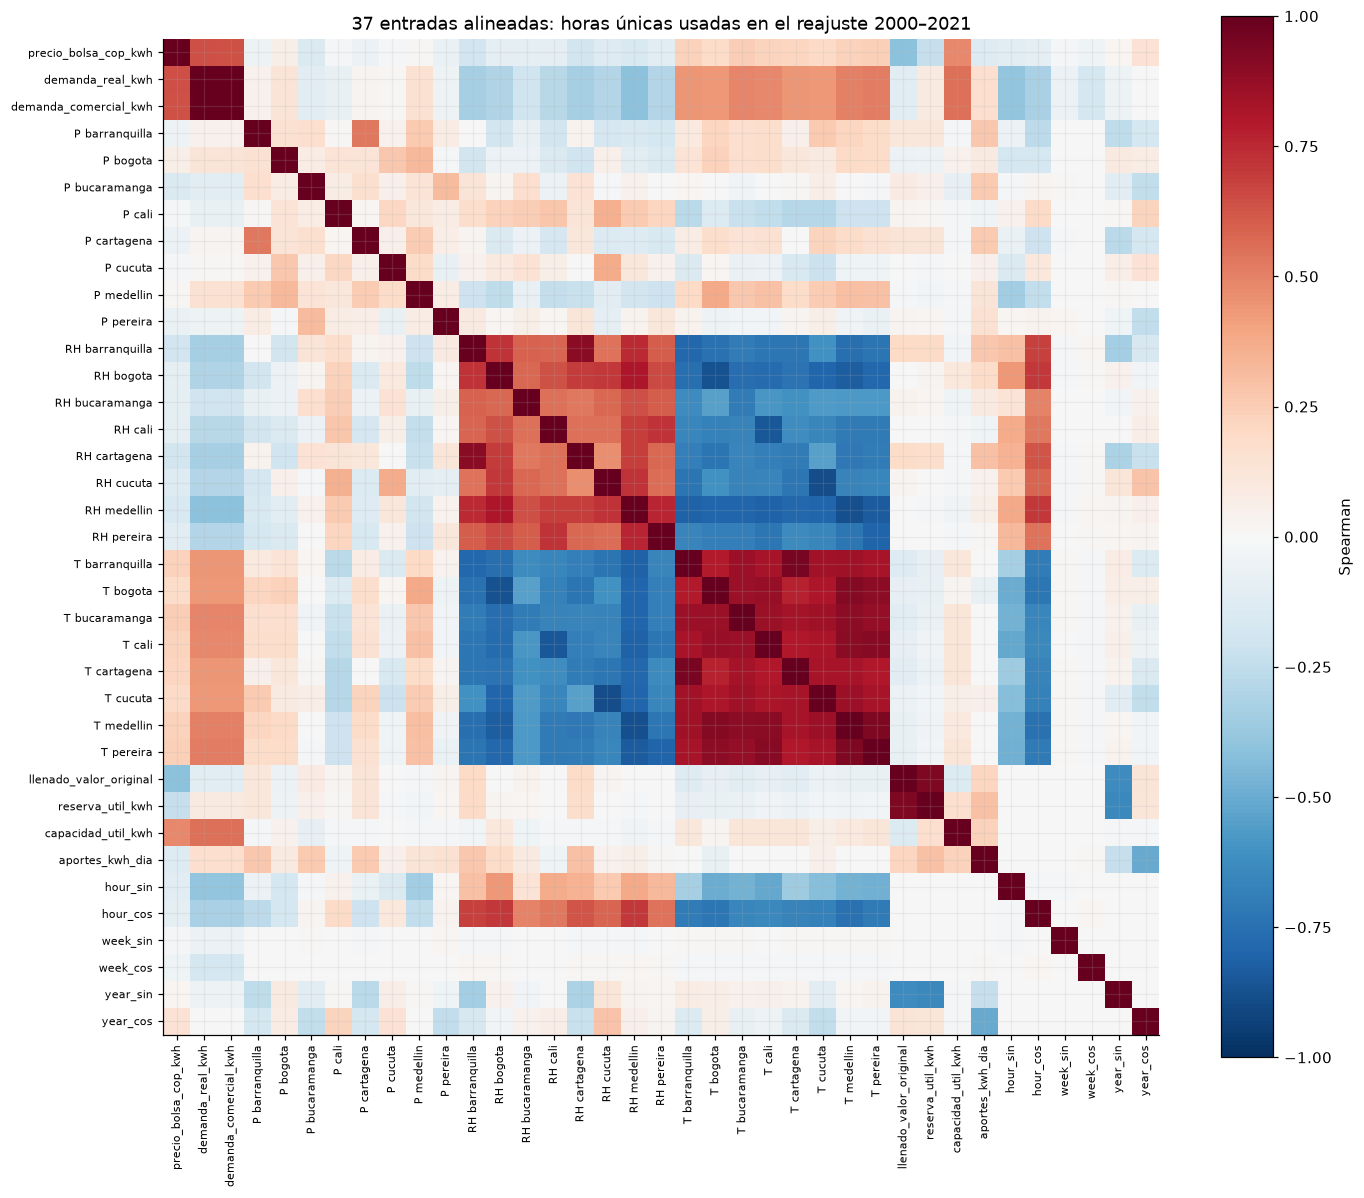

In [33]:
correlation = actual.corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
names = [c.replace('relative_humidity_2m_pct_', 'RH ').replace('temperature_2m_c_', 'T ').replace('precipitation_preceding_hour_mm_', 'P ') for c in actual]
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
ax.set_yticks(range(len(names)), names, fontsize=7)
ax.set_title('37 entradas alineadas: horas únicas usadas en el reajuste 2000–2021')
fig.colorbar(im, ax=ax, label='Spearman')
figure(fig, 'eda_correlaciones_37_entradas')

In [34]:
scope = dict(period_start=config['development_start'], period_end_exclusive=config['development_end_exclusive'], raw_hours=len(features), feature_count=features.shape[1], feature_names=list(features.columns), refit_windows=len(refit_origins), refit_input_rows=len(actual), refit_input_start=str(actual.index[0]), refit_input_end=str(actual.index[-1]), feature_preprocessing_matches_saved_refit=True, search_folds_match_saved_audit=True, test_values_read=False, model_training_repeated=False, unit='Una fila horaria única; las ventanas superpuestas no se cuentan como observaciones independientes.')
(RESULTS / 'eda_training_scope.json').write_text(json.dumps(scope, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

1858